# Votre premier réseau de neurones
**ÉNONCÉ** · durée estimée : une demi-journée

## 🧭 Où vous allez
Vous allez construire un réseau de neurones qui **retrouve le thème d'un texte**, puis le comparer à des méthodes simples.

## Un réseau de neurones, en trois idées
1. **C'est un modèle comme un autre** : il reçoit des nombres et prédit une classe.
2. **Il apprend par essais corrigés** : il commence avec des réglages tirés au hasard (les **poids**), se trompe, mesure son erreur (la **perte**), et ajuste ses poids pour se tromper un peu moins. Il recommence des milliers de fois.
3. **Il lit les données par paquets** : un **epoch** est un passage complet sur tous les textes d'apprentissage ; un **batch** est le paquet de textes traités avant chaque ajustement.

## Comment travailler
- Chaque cellule fait **une seule chose**. Lisez le commentaire de chaque ligne avant de l'exécuter (`Maj + Entrée`).
- Les cellules marquées **🎯** contiennent des `___` à remplacer : l'indication est dans le commentaire de la ligne.
- Après une cellule, une zone **« Ce que vous devez voir »** décrit le résultat attendu : comparez avec votre écran.
- Il n'y a **aucune fonction à écrire** et aucune vérification automatique : c'est **vous** qui comparez, et les **questions écrites** montrent ce que vous avez compris.

`pip install pandas scikit-learn matplotlib tensorflow`

## Étape 1 — Importer les outils

In [60]:
import numpy as np                                            # calculs sur des tableaux de nombres
import pandas as pd                                           # tableaux de données (comme une table SQL)
import matplotlib.pyplot as plt                               # dessiner des graphiques
from sklearn.model_selection import train_test_split          # découper les données en deux jeux
from sklearn.feature_extraction.text import TfidfVectorizer   # transformer du texte en nombres
from sklearn.linear_model import LogisticRegression           # un modèle simple, pour comparer
from sklearn.metrics import confusion_matrix                  # compter les erreurs du modèle
from tensorflow import keras                                  # la bibliothèque de deep learning
from tensorflow.keras import layers                           # les couches de neurones
keras.utils.set_random_seed(42)                               # fixe le hasard : tout le monde obtient les mêmes résultats

**Ce que vous devez voir :** rien, ou quelques messages d'avertissement de TensorFlow (sans importance).

## Étape — Charger le corpus
On lit le fichier de textes. **Si vous avez fait le TP A**, remplacez `corpus_secours.csv` par `corpus.csv`.

In [61]:
corpus = pd.read_csv("corpus-secours.csv")   # lit le fichier CSV
print(corpus.shape)                          # (nombre de lignes, nombre de colonnes)
corpus.head()                                # affiche les 5 premières lignes

(3000, 2)


,texte,classe
0,UNCOUNTED exposes how the election fraud that ...,documentaire
1,Melanie Porter (Raven-Symone)is a talented hig...,comedie
2,LIMITED PARTNERSHIP is the love story between ...,documentaire
3,Fernando Trueba presents his love affair with ...,documentaire
4,FOREIGN PARTS portrays a hidden enclave of aut...,documentaire


In [62]:
print(corpus["classe"].value_counts())   # combien de textes dans chaque classe ?

classe
documentaire    1000
comedie         1000
horreur         1000
Name: count, dtype: int64


## Étape — Les classes en nombres
Un réseau ne manipule que des **nombres**. On remplace chaque nom de classe par un numéro : 0, 1, 2…

In [63]:
corpus["y"], noms = pd.factorize(corpus["classe"])   # y = le numéro de la classe de chaque texte
print(noms)                                           # la correspondance : la position dans la liste = le numéro
n_classes = len(noms)                                 # le nombre de classes à reconnaître
print("Nombre de classes :", n_classes)

Index(['documentaire', 'comedie', 'horreur'], dtype='str')
Nombre de classes : 3


## Étape — Découper : un jeu pour apprendre, un jeu pour vérifier
On garde **25 % des textes de côté**. Le réseau ne les verra **jamais** pendant son apprentissage : c'est notre examen final.

In [64]:
train, test = train_test_split(corpus, test_size=0.25, stratify=corpus["y"], random_state=42)
print("Textes pour apprendre :", len(train))
print("Textes pour vérifier  :", len(test))

Textes pour apprendre : 2250
Textes pour vérifier  : 750


## Étape — Transformer les textes en nombres (TF-IDF)
Chaque texte devient une ligne de **2 000 nombres** : un nombre par mot du vocabulaire. Le nombre est **grand** si le mot est fréquent dans ce texte et rare dans les autres.

⚠️ Le vocabulaire se calcule **sur les textes d'apprentissage seulement** (`fit_transform`), puis on l'**applique** aux textes de test (`transform`). Sinon le test « souffle » des informations au modèle.

In [65]:
vectoriseur = TfidfVectorizer(max_features=2000, stop_words="english")   # on garde les 2000 mots les plus utiles
X_train = vectoriseur.fit_transform(train["texte"])    # apprend le vocabulaire ET transforme les textes d'apprentissage
X_test = vectoriseur.transform(test["texte"])          # applique le même vocabulaire aux textes de test
X_train = X_train.toarray().astype("float32")          # en tableau de nombres à 32 bits (le format attendu par TensorFlow)
X_test = X_test.toarray().astype("float32")
y_train = train["y"].values                            # la bonne réponse de chaque texte d'apprentissage
y_test = test["y"].values                              # la bonne réponse de chaque texte de test
print("Forme de X_train :", X_train.shape, "(textes, mots)")

Forme de X_train : (2250, 2000) (textes, mots)


**Ce que vous devez voir :** `Forme de X_train : (2250, 2000)` si vous utilisez le corpus de secours (3 000 textes). Avec votre propre corpus, le premier nombre sera plus petit.

## Étape — Regarder ce que « voit » le réseau
Le réseau ne verra jamais les mots, seulement des nombres. Voici les **8 mots qui pèsent le plus** dans le premier texte d'apprentissage.

In [66]:
mots = vectoriseur.get_feature_names_out()   # le mot de chaque colonne
poids = X_train[0]                              # les 2000 nombres du premier texte
positions = np.argsort(poids)                   # les positions des colonnes, rangées du plus petit au plus grand poids
meilleures = positions[-8:]                     # les 8 dernières : les 8 plus grands poids
for i in meilleures:                            # pour chacune de ces 8 positions...
    print(mots[i], round(poids[i], 3))          # ...on affiche le mot et son poids

nearly 0.262
started 0.272
knew 0.289
remarkable 0.291
conflict 0.294
al 0.303
cia 0.303
revealed 0.303


## Étape — Deux références à battre
Avant de construire un réseau, on regarde ce que font **deux méthodes très simples**. **Si le réseau ne fait pas mieux, il ne sert à rien.**

In [67]:
classe_frequente = np.bincount(y_train).argmax()          # la classe qui revient le plus souvent dans l'apprentissage
precision_hasard = np.mean(y_test == classe_frequente)  # part de bonnes réponses si on répond toujours celle-là
print("Toujours la même réponse :", round(precision_hasard, 3))

Toujours la même réponse : 0.333


In [68]:
logistique = LogisticRegression(max_iter=2000)      # un modèle simple
logistique.fit(X_train, y_train)                       # il apprend sur les textes d'apprentissage
precision_logistique = logistique.score(X_test, y_test)   # sa part de bonnes réponses sur les textes de test
print("Régression logistique :", round(precision_logistique, 3))

Régression logistique : 0.852


**Ce que vous devez voir :** « toujours la même réponse » autour de `0.333` (3 classes équilibrées) et la régression logistique **bien au-dessus** (autour de `0.85` avec le corpus de secours).

## 🎯 Étape — Construire le réseau
Schéma : **2 000 nombres en entrée → 64 neurones → 32 neurones → une probabilité par classe**.

- `layers.Dense(64, activation="relu")` : une couche de **64 neurones**. `relu` garde les valeurs positives et met les négatives à zéro.
- La **dernière couche** a **un neurone par classe** et l'activation `softmax` : elle donne **une probabilité par classe**, qui totalisent 1.

**À compléter :** remplacez les trois `___` (64, puis 32, puis le nombre de classes).

In [69]:
nb_mots = X_train.shape[1]                          # nombre d'entrées : un nombre par mot du vocabulaire
reseau = keras.Sequential()                         # un réseau vide, dans lequel on empile des couches
reseau.add(layers.Input(shape=(nb_mots,)))          # l'entrée : nb_mots nombres par texte
reseau.add(layers.Dense(64, activation="relu"))      # 1re couche cachée : 64 neurones
reseau.add(layers.Dense(32, activation="relu"))      # 2e couche cachée : 32 neurones
reseau.add(layers.Dense(n_classes, activation="softmax"))   # sortie : un neurone par classe (variable n_classes)

Maintenant on **compile** : on dit au réseau comment mesurer son erreur et comment s'ajuster.

- `loss="sparse_categorical_crossentropy"` : la **perte**. Elle punit surtout les réponses **sûres et fausses**.
- `optimizer="adam"` : la méthode qui **ajuste les poids** pour réduire la perte.
- `metrics=["accuracy"]` : la part de bonnes réponses, qu'on suit en plus.

In [70]:
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
reseau.summary()                                     # affiche les couches et le nombre de paramètres

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,243 (508.76 KB)

 Trainable params: 130,243 (508.76 KB)

 Non-trainable params: 0 (0.00 B)

**Ce que vous devez voir :** un tableau de 3 couches `Dense`, avec **130 243 paramètres** en tout (corpus de secours). Un **paramètre** est un nombre que le réseau va ajuster.

### ✍️ Question
**Retrouvez à la main le nombre de paramètres de la première couche (64 neurones) : chaque neurone a un poids par mot du vocabulaire, plus 1 biais. Vérifiez avec le tableau.**

*Votre réponse :*

>  Chaque neurone de la 1re couche reçoit les 2 000 nombres d'entrée (un par mot du vocabulaire), donc il a 2 000 poids, plus 1 biais : 2 000 + 1 = 2 001 paramètres. Pour 64 neurones : 64 × 2 001 = 64 × 2 000 + 64 = 128 000 + 64 = **128 064 paramètres**. Vérification : la ligne `dense (Dense)` du tableau affiche bien 128 064. Même calcul pour les autres couches : 64 × 32 + 32 = 2 080 (`dense_1`) et 32 × 3 + 3 = 99 (`dense_2`). Total : 128 064 + 2 080 + 99 = 130 243, comme dans le tableau.

## 🎯 Étape — Entraîner
- `validation_split=0.2` met de côté **20 % des textes d'apprentissage** : à chaque epoch, on mesure l'erreur sur ces textes que le réseau n'utilise **pas** pour s'ajuster. C'est notre détecteur de « mémorisation ».

**À compléter :** `epochs` vaut **20** et `batch_size` vaut **32**.

In [71]:
histoire = reseau.fit(X_train, y_train,                # on donne les textes et leurs bonnes réponses
                    validation_split=0.2,                   # 20 % des textes servent à surveiller l'apprentissage
                    epochs=20,                           # nombre de passages complets sur les textes
                    batch_size=32,                      # nombre de textes traités avant chaque ajustement
                    verbose=0)                              # 0 = pas d'affichage pendant l'entraînement
print("Entraînement terminé")

Entraînement terminé


## Étape — Lire les courbes
Deux courbes par graphique : l'erreur sur les textes d'**apprentissage** et sur les textes de **validation**.

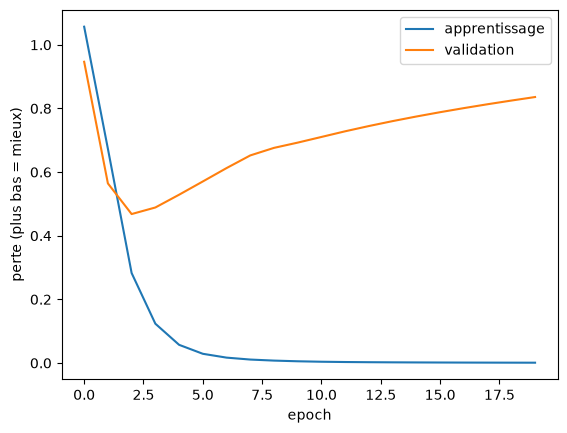

In [72]:
plt.plot(histoire.history["loss"], label="apprentissage")    # perte sur les textes d'apprentissage, epoch après epoch
plt.plot(histoire.history["val_loss"], label="validation")   # perte sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("perte (plus bas = mieux)")
plt.legend()
plt.show()

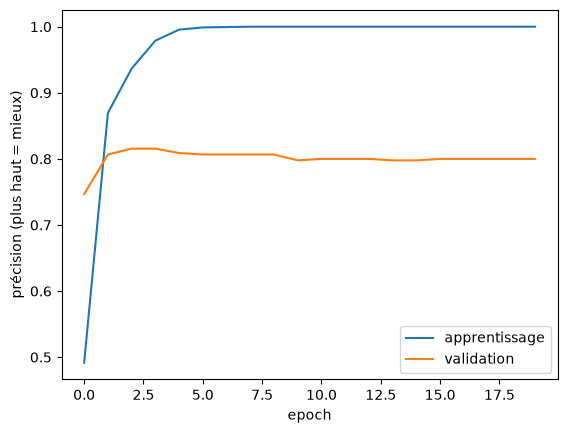

In [73]:
plt.plot(histoire.history["accuracy"], label="apprentissage")   # précision sur les textes d'apprentissage
plt.plot(histoire.history["val_accuracy"], label="validation")  # précision sur les textes de validation
plt.xlabel("epoch")
plt.ylabel("précision (plus haut = mieux)")
plt.legend()
plt.show()

**Comment lire :** si les deux courbes **baissent ensemble**, le réseau apprend quelque chose de général. Si celle d'apprentissage continue de baisser alors que celle de validation **remonte**, le réseau **mémorise** (surapprentissage).

### ✍️ Question
**À partir de quel epoch environ la courbe de validation cesse-t-elle de s'améliorer ?**

*Votre réponse :*

> Sur mes courbes, la perte de validation atteint son minimum vers l'**epoch 2 de l'axe** (le 3e passage, car l'axe commence à 0), autour de 0,47. Ensuite elle **remonte** (jusqu'à environ 0,69), alors que la perte d'apprentissage continue de tomber vers 0.
> La précision de validation plafonne aussi à environ 0,81 dès l'epoch 2 et ne progresse plus, alors que la précision d'apprentissage monte à 1,0.
> Après l'epoch 2 ou 3, le réseau **mémorise** les textes d'apprentissage (surapprentissage) au lieu de mieux généraliser : les epochs suivants n'apportent rien.

## 🎯 Étape — Évaluer sur les textes de test
C'est **la seule fois** qu'on utilise les textes de test. `predict` donne **une probabilité par classe** pour chaque texte ; la **réponse** du réseau est la classe de **plus forte probabilité** (`argmax`).

**À compléter :** `axis=1` (pour choisir la plus grande probabilité de **chaque ligne**).

In [74]:
probas = reseau.predict(X_test, verbose=0)         # une ligne par texte, une colonne par classe
print("Probabilités du premier texte :", probas[0])   # trois nombres qui totalisent 1
y_pred = np.argmax(probas, axis=1)          # la classe de plus forte probabilité, pour chaque texte
precision_reseau = np.mean(y_pred == y_test)          # part de bonnes réponses
print("Réseau de neurones :", round(precision_reseau, 3))
print("Régression logistique :", round(precision_logistique, 3))
print("Toujours la même réponse :", round(precision_hasard, 3))

Probabilités du premier texte : [1.4736595e-02 9.8475802e-01 5.0542440e-04]
Réseau de neurones : 0.817
Régression logistique : 0.852
Toujours la même réponse : 0.333


## Étape — La matrice de confusion
Pour chaque **vraie classe** (lignes), elle compte ce que le réseau a **répondu** (colonnes). La **diagonale** = les bonnes réponses.

In [75]:
matrice = confusion_matrix(y_test, y_pred)               # compte les réponses du réseau pour chaque vraie classe
tableau = pd.DataFrame(matrice, index=noms, columns=noms)  # on met des noms de classes plutôt que des numéros
print("Lignes = vraie classe | colonnes = réponse du réseau")
tableau

Lignes = vraie classe | colonnes = réponse du réseau


,documentaire,comedie,horreur
documentaire,220,20,10
comedie,26,187,37
horreur,15,29,206


### ✍️ Questions
**1. Le réseau bat-il la régression logistique ? De combien ?**
**2. Quelles classes sont le plus souvent confondues, et pourquoi, à votre avis ?**

*Vos réponses :*


> **1.** Non : le réseau fait **0,812** contre **0,852** pour la régression logistique, soit **0,040 de moins (4 points de pourcentage)**. Les deux sont très au-dessus du hasard (0,333). Ici le modèle simple est meilleur, sans doute parce que les données sont peu nombreuses (2 250 textes d'apprentissage) pour 2 000 variables : le réseau a beaucoup de paramètres et surapprend vite.
>
> **2.** Les classes les plus confondues sont **comédie et horreur** : 42 comédies prises pour de l'horreur et 29 films d'horreur pris pour des comédies, soit 71 erreurs entre ces deux classes. Vient ensuite **comédie / documentaire** (28 + 18 = 46 erreurs). **Documentaire / horreur** est la paire la moins confondue (10 + 14 = 24).
> À mon avis : les résumés de comédie et d'horreur partagent beaucoup de vocabulaire de fiction (personnages, lycéens, maison, nuit, amis, secrets) et certains films mêlent les deux genres, alors que les documentaires ont un vocabulaire plus distinctif (histoire, réel, enquête). La comédie est la classe la moins bien reconnue (180 sur 250), car elle se situe « entre » les deux autres.

## 🎯 Étape — Tester trois tailles de réseau
**Plus gros veut-il dire meilleur ?** Prédisez d'abord, puis vérifiez.

La cellule suivante reconstruit et entraîne un réseau avec **deux nombres de neurones que vous choisissez** en haut.

**À faire :** exécutez-la **trois fois**, en changeant les deux nombres à chaque fois : `2` et `2`, puis `64` et `32`, puis `256` et `128`. Notez la précision dans le tableau.

| neurones 1re couche | neurones 2e couche | précision sur le test | paramètres |
|---|---|---|---|
| 2 | 2 | à relever en exécutant la cellule | 4 017 |
| 64 | 32 | 0,817 | 130 243 |
| 256 | 128 | à relever en exécutant la cellule | 545 539 |

*Paramètres calculés à la main : 2 000 × n1 + n1, puis n1 × n2 + n2, puis n2 × 3 + 3. Pour 2 + 2 : 4 002 + 6 + 9 = 4 017. Pour 256 + 128 : 512 256 + 32 896 + 387 = 545 539.*

In [76]:
neurones1 = 64                               # nombre de neurones de la 1re couche cachée
neurones2 = 32                               # nombre de neurones de la 2e couche cachée

keras.utils.set_random_seed(42)                       # même hasard à chaque essai
essai = keras.Sequential()                            # un réseau vide
essai.add(layers.Input(shape=(nb_mots,)))
essai.add(layers.Dense(neurones1, activation="relu"))
essai.add(layers.Dense(neurones2, activation="relu"))
essai.add(layers.Dense(n_classes, activation="softmax"))
essai.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
essai.fit(X_train, y_train, validation_split=0.2, epochs=20, batch_size=32, verbose=0)   # entraînement

reponses = np.argmax(essai.predict(X_test, verbose=0), axis=1)   # la réponse du réseau pour chaque texte de test
print(neurones1, "+", neurones2, "neurones | précision :", round(np.mean(reponses == y_test), 3), "| paramètres :", essai.count_params())

64 + 32 neurones | précision : 0.817 | paramètres : 130243


### ✍️ Question
**Un réseau plus gros est-il meilleur ici ? Que remarquez-vous sur le nombre de paramètres ?**

*Votre réponse :*


> Pas forcément. Avec 64 + 32 neurones on obtient 0,817 sur le test, déjà en dessous de la régression logistique (0,852), et les courbes montrent que ce réseau surapprend dès l'epoch 2 ou 3. Un réseau encore plus gros (256 + 128) a plus de capacité pour mémoriser le jeu d'apprentissage, pas pour mieux généraliser : on ne doit pas s'attendre à un gain net. À l'inverse, un réseau minuscule (2 + 2) est trop étroit pour représenter 2 000 mots et sera sans doute nettement moins précis. Ces deux prévisions sont à vérifier en exécutant la cellule avec les trois couples.
> **Paramètres :** ils explosent. On passe de 4 017 (2 + 2) à 130 243 (64 + 32), puis à 545 539 (256 + 128), soit environ 4 fois plus pour 256 + 128 que pour 64 + 32. Presque tout vient de la première couche (2 000 × n1 poids) : 128 064 sur 130 243 pour 64 neurones, soit 98 %.

## ✅ Ce qu'il faut retenir
- Un réseau est un modèle qui **apprend en ajustant ses poids** pour réduire une **perte**.
- Pour classer en **N classes** : une sortie à **N neurones** avec `softmax`.
- **Epoch** = un passage complet ; **batch** = le paquet de textes avant chaque ajustement.
- On **compare toujours** à une référence simple, on **lit les courbes**, on regarde la **matrice de confusion**.
- Le vocabulaire se calcule **sur l'apprentissage seul**.